# Midterm 2 — Integrated Evidence Notebook

This notebook consolidates **already-saved outputs** from the project repository. It does not train or refit models.

Expected location: save this notebook under `notebooks/` in the main repository, or run it from the repository root. All source paths are repository-relative.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "reports").is_dir() and (p / "scripts").is_dir())
BASE = ROOT / "reports" / "tables" / "midterm2-20261104"
W4 = ROOT / "reports" / "tables" / "week4-comparison-20261111"
H1 = ROOT / "reports" / "tables" / "h1-ablation-20261109"
W3 = ROOT / "reports" / "tables" / "week3-review-20261109"
OUT = ROOT / "reports" / "combined-midterm2-20261111"
OUT.mkdir(parents=True, exist_ok=True)

def read_csv(path):
    path = ROOT / path
    if not path.exists():
        raise FileNotFoundError(f"Required saved output not found: {path}")
    return pd.read_csv(path, encoding="utf-8-sig")

def read_json(path):
    path = ROOT / path
    if not path.exists():
        raise FileNotFoundError(f"Required saved output not found: {path}")
    return json.loads(path.read_text(encoding="utf-8"))

print("Repository:", ROOT)
print("Output directory:", OUT)

Repository: c:\Users\MSI\Downloads\reddit-community-evolution-work
Output directory: c:\Users\MSI\Downloads\reddit-community-evolution-work\reports\combined-midterm2-20261111


## 1. Load and validate saved full-study outputs

In [2]:
a1_overall = read_csv("reports/tables/midterm2-20261104/A1/tables/A1_overall_macro_summary.csv")
a1_class = read_csv("reports/tables/midterm2-20261104/A1/tables/A1_overall_class_metrics.csv")
a1_month = read_csv("reports/tables/midterm2-20261104/A1/tables/A1_monthly_macro_summary.csv")
a2_strata = read_csv("reports/tables/midterm2-20261104/A2/tables/A2_stratified_macro_summary.csv")
a3_numeric = read_csv("reports/tables/midterm2-20261104/A3/tables/A3_numeric_comparison.csv")
a3_size = read_csv("reports/tables/midterm2-20261104/A3/tables/A3_status_by_size_band.csv")
a3_history = read_csv("reports/tables/midterm2-20261104/A3/tables/A3_status_by_history.csv")
b_month = read_csv("reports/tables/midterm2-20261104/B/tables/B_monthly_coverage.csv")
b_size = read_csv("reports/tables/midterm2-20261104/B/tables/B_size_coverage.csv")
b_history = read_csv("reports/tables/midterm2-20261104/B/tables/B_history_coverage.csv")
errors = read_csv("reports/tables/midterm2-20261104/error_analysis/tables/error_by_true_class.csv")
error_pairs = read_csv("reports/tables/midterm2-20261104/error_analysis/tables/misclassification_pairs.csv")

# Fixed-cohort and status-count checks
assert set(a1_overall["seed"].unique()) == {42, 43, 44}
assert a1_overall["n"].nunique() == 1 and int(a1_overall["n"].iloc[0]) == 1269
assert int(a3_size[["resolved", "unresolved", "censored"]].to_numpy().sum()) == 11745
assert int(a3_history[["resolved", "unresolved", "censored"]].to_numpy().sum()) == 11745

status_totals = {
    "resolved": int(a3_size["resolved"].sum()),
    "unresolved": int(a3_size["unresolved"].sum()),
    "censored": int(a3_size["censored"].sum()),
}
coverage = status_totals["resolved"] / (status_totals["resolved"] + status_totals["unresolved"])
print(status_totals, "community-month coverage =", round(coverage, 6))

{'resolved': 7490, 'unresolved': 4072, 'censored': 183} community-month coverage = 0.647812


## 2. A1 — Overall, class and monthly performance

In [3]:
overall = (a1_overall.groupby("model", as_index=False)
           .agg(macro_f1=("macro_f1_six", "mean"),
                accuracy=("accuracy", "mean"),
                n_per_seed=("n", "max"),
                seeds=("seed", "nunique"))
           .sort_values("macro_f1", ascending=False))
display(overall)
overall.to_csv(OUT / "A1_overall_model_summary.csv", index=False)

proposed_class = a1_class[(a1_class.model == "hier_lr_dynamic") & (a1_class.seed == 42)].copy()
display(proposed_class[["label","support","precision","recall","f1","to_dissolve","predicted"]])
proposed_class.to_csv(OUT / "A1_proposed_per_class_seed42.csv", index=False)

proposed_month = (a1_month[a1_month.model == "hier_lr_dynamic"]
                  .groupby("stratum", as_index=False)
                  .agg(n=("n","max"), macro_f1=("macro_f1_six","mean"), accuracy=("accuracy","mean")))
display(proposed_month)
proposed_month.to_csv(OUT / "A1_proposed_monthly_summary.csv", index=False)

,model,macro_f1,accuracy,n_per_seed,seeds
17,hier_lr_dynamic,0.411738,0.904649,1269,3
1,A_no_context_drift_matched,0.406851,0.908589,1269,3
15,hier_hgb_dynamic,0.388045,0.909377,1269,3
16,hier_hgb_static,0.372762,0.915682,1269,3
9,flat_hgb_SHL,0.368263,0.945626,1269,3
2,A_no_dynamics_matched,0.364298,0.917258,1269,3
10,flat_hgb_dynamic,0.364092,0.808511,1269,3
13,flat_lr_dynamic,0.361585,0.949567,1269,3
18,hier_lr_static,0.347735,0.918834,1269,3
11,flat_hgb_static,0.345061,0.944838,1269,3


,label,support,precision,recall,f1,to_dissolve,predicted
306,stable,4,0.000000,0.000000,0.000000,3,18
307,grow,19,0.069767,0.157895,0.096774,14,43
308,shrink,25,0.413793,0.480000,0.444444,6,29
309,merge,15,0.272727,0.200000,0.230769,8,11
310,split,39,0.794118,0.692308,0.739726,0,34
311,dissolve,1167,0.972663,0.945159,0.958714,1103,1134


,stratum,n,macro_f1,accuracy
0,2018-01,144,0.382429,0.902778
1,2018-02,116,0.434921,0.896552
2,2018-03,150,0.262226,0.846667
3,2018-04,147,0.244505,0.911565
4,2018-05,123,0.288059,0.943089
5,2018-06,140,0.469001,0.914286
6,2018-07,146,0.354405,0.883562
7,2018-08,160,0.549562,0.937500
8,2018-09,143,0.460806,0.909091


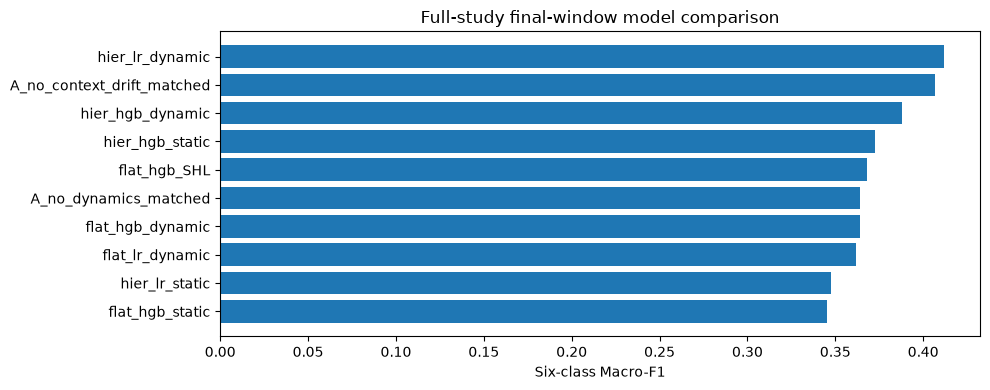

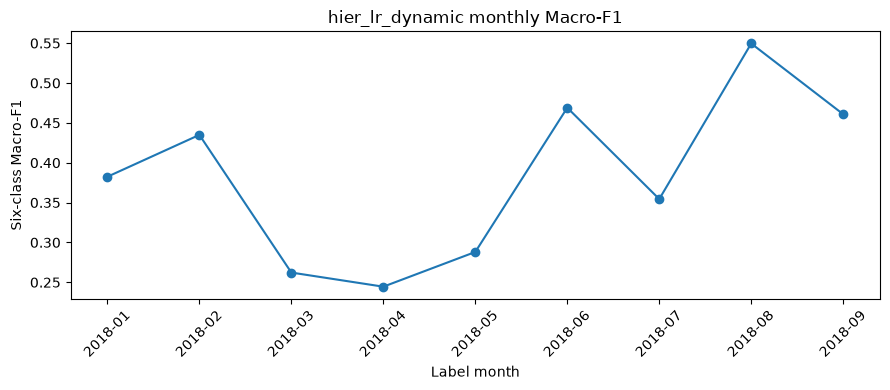

In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
plot_df = overall.head(10).sort_values("macro_f1")
ax.barh(plot_df["model"], plot_df["macro_f1"])
ax.set_xlabel("Six-class Macro-F1")
ax.set_title("Full-study final-window model comparison")
fig.tight_layout()
fig.savefig(OUT / "A1_overall_macro_f1.png", dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(proposed_month["stratum"], proposed_month["macro_f1"], marker="o")
ax.set_xlabel("Label month")
ax.set_ylabel("Six-class Macro-F1")
ax.set_title("hier_lr_dynamic monthly Macro-F1")
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
fig.savefig(OUT / "A1_monthly_macro_f1.png", dpi=160)
plt.show()

## 3. A2 — Size and history strata

In [5]:
proposed_strata = a2_strata[(a2_strata.model == "hier_lr_dynamic") & (a2_strata.seed == 42)].copy()
display(proposed_strata[["axis","stratum","n","macro_f1_six","accuracy"]])
proposed_strata.to_csv(OUT / "A2_proposed_strata_seed42.csv", index=False)

,axis,stratum,n,macro_f1_six,accuracy
816,size,2,857,0.207848,0.912485
817,size,3-4,239,0.238010,0.924686
818,size,5-20,97,0.165803,0.989691
819,size,>20,76,0.320767,0.644737
820,lineage_history,available,105,0.424646,0.771429
821,lineage_history,missing,1164,0.393311,0.916667
822,member_activity_history,available,730,0.414272,0.867123
823,member_activity_history,missing_or_not_recorded,539,0.200056,0.955473
824,size_history,2|available,68,0.154270,0.823529
825,size_history,2|missing,789,0.220442,0.920152


## 4. A3/B — Coverage and resolved/unresolved comparisons

In [6]:
coverage_by_size = b_size.copy()
coverage_by_history = b_history.copy()
display(coverage_by_size)
display(coverage_by_history)
coverage_by_size.to_csv(OUT / "B_coverage_by_size.csv", index=False)
coverage_by_history.to_csv(OUT / "B_coverage_by_history.csv", index=False)

# Show selected distribution summaries; no inferential tests are performed here.
selected_vars = ["size", "density", "community_age", "past_growth", "past_retention",
                 "inflow_fraction", "outflow_fraction", "thread_activity",
                 "active_member_fraction", "context_drift_js"]
resolved_unresolved = a3_numeric[
    a3_numeric["variable"].isin(selected_vars) &
    a3_numeric["status"].isin(["resolved", "unresolved"])
][["status","variable","n_rows","mean","median","q25","q75","missing_rate"]]
display(resolved_unresolved)
resolved_unresolved.to_csv(OUT / "A3_resolved_unresolved_selected_features.csv", index=False)

,size_band,resolved,unresolved,observed_transitions,coverage,censored_separate
0,2,4810,2770,7580,0.634565,130
1,3-4,1569,828,2397,0.654568,34
2,5-20,737,227,964,0.764523,6
3,>20,374,247,621,0.602254,13


,history_missing,resolved,unresolved,observed_transitions,coverage,censored_separate
0,0,503,374,877,0.573546,13
1,1,6987,3698,10685,0.653907,170


,status,variable,n_rows,mean,median,q25,q75,missing_rate
0,resolved,size,7490,189.269159,2.000000,2.000000,3.000000,0.0
4,resolved,density,7490,0.803230,1.000000,0.666667,1.000000,0.0
5,resolved,community_age,7490,1.019092,1.000000,1.000000,1.000000,0.0
8,resolved,past_growth,7490,25.976939,0.000000,0.000000,0.000000,0.0
9,resolved,past_retention,7490,0.016102,0.000000,0.000000,0.000000,0.0
10,resolved,inflow_fraction,7490,0.017957,0.000000,0.000000,0.000000,0.0
11,resolved,outflow_fraction,7490,0.051054,0.000000,0.000000,0.000000,0.0
13,resolved,thread_activity,7490,0.451694,0.405465,0.405465,0.405465,0.0
14,resolved,active_member_fraction,7490,0.893987,1.000000,0.997937,1.000000,0.0
29,resolved,context_drift_js,7490,0.065289,0.000000,0.000000,0.001457,0.0


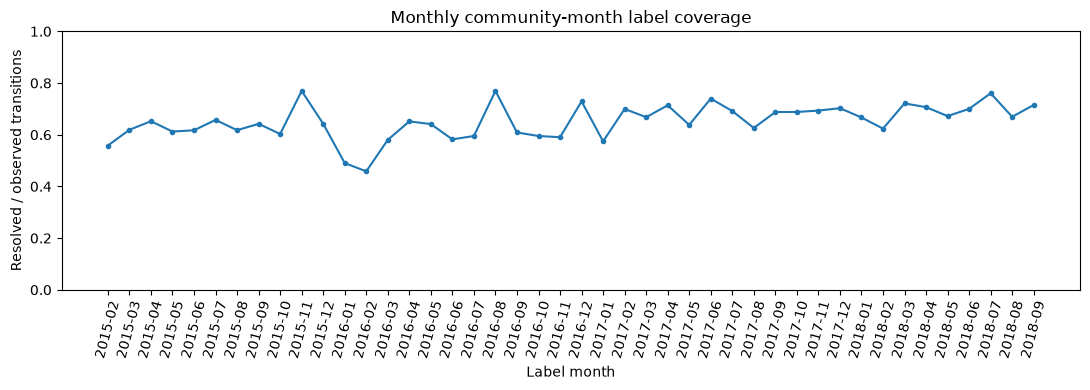

In [7]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(b_month["label_month"], b_month["coverage"], marker="o", markersize=3)
ax.set_ylim(0, 1)
ax.set_ylabel("Resolved / observed transitions")
ax.set_xlabel("Label month")
ax.set_title("Monthly community-month label coverage")
ax.tick_params(axis="x", rotation=75)
fig.tight_layout()
fig.savefig(OUT / "B_monthly_coverage.png", dpi=160)
plt.show()

## 5. Error analysis

In [8]:
display(errors)
display(error_pairs.head(15))
errors.to_csv(OUT / "error_by_true_class.csv", index=False)
error_pairs.to_csv(OUT / "misclassification_pairs.csv", index=False)

,truth,support,correct,errors,recall,error_rate
0,stable,4,0,4,0.000000,1.000000
1,grow,19,3,16,0.157895,0.842105
2,shrink,25,12,13,0.480000,0.520000
3,merge,15,3,12,0.200000,0.800000
4,split,39,27,12,0.692308,0.307692
5,dissolve,1167,1103,64,0.945159,0.054841


,truth,predicted,count
0,dissolve,grow,37
1,grow,dissolve,14
2,dissolve,stable,14
3,split,shrink,12
4,merge,dissolve,8
5,dissolve,merge,8
6,shrink,split,7
7,shrink,dissolve,6
8,dissolve,shrink,5
9,stable,dissolve,3


## 6. Week 4 — Proposed versus HGB and baseline comparison

In [9]:
w4_baselines = read_csv("reports/tables/week4-comparison-20261111/primary_baseline_comparison.csv")
w4_class = read_csv("reports/tables/week4-comparison-20261111/per_class_metrics.csv")
w4_pairs = read_csv("reports/tables/week4-comparison-20261111/paired_wins_losses_summary.csv")
w4_by_class = read_csv("reports/tables/week4-comparison-20261111/paired_wins_losses_by_class.csv")
w4_recon = read_json("reports/tables/week4-comparison-20261111/reconciliation_summary.json")
display(w4_baselines)
display(w4_pairs[w4_pairs.comparator_model == "hier_hgb_dynamic"])
display(w4_class[w4_class.model.isin(["hier_lr_dynamic","hier_hgb_dynamic"])])
assert w4_recon["status"] == "PASS"
assert w4_recon["both_correct"] == 1119
assert w4_recon["proposed_only"] == 29
assert w4_recon["hgb_only"] == 35
assert w4_recon["both_wrong"] == 86

,model,role,n_per_seed,macro_f1_mean,macro_f1_sd,accuracy_mean,macro_f1_seed_42,macro_f1_seed_43,macro_f1_seed_44
0,hier_lr_dynamic,Proposed (hier_lr_dynamic),1269,0.4117,0.0000,0.9046,0.4117,0.4117,0.4117
1,hier_hgb_dynamic,Reference Comparator (Hierarchical HGB Dynamic),1269,0.3880,0.0000,0.9094,0.3880,0.3880,0.3880
2,flat_lr_dynamic,Linear Comparator (Flat LR Dynamic),1269,0.3616,0.0000,0.9496,0.3616,0.3616,0.3616
3,B4_logreg,Linear Baseline (Logistic Regression),1269,0.3311,0.0000,0.9472,0.3311,0.3311,0.3311
4,B2_random_forest,Tree Baseline (Random Forest),1269,0.2565,0.0033,0.1524,0.2529,0.2594,0.2573
5,B5_matched_boosting,Tree Baseline (Matched Boosting HGB),1269,0.2330,0.0000,0.1789,0.2330,0.2330,0.2330
6,B1_majority,Trivial Baseline (Majority),1269,0.1597,0.0000,0.9196,0.1597,0.1597,0.1597
7,B1_persistence,Heuristic Baseline (Persistence),1269,0.1562,0.0000,0.8605,0.1562,0.1562,0.1562
8,A_no_context_drift_matched,Ablation Control (No Context Drift Matched),1269,0.4069,0.0000,0.9086,0.4069,0.4069,0.4069
9,hier_hgb_static,Control (Hierarchical HGB Static),1269,0.3728,0.0000,0.9157,0.3728,0.3728,0.3728


,proposed_model,comparator_model,seed,total_cases,both_correct,proposed_only (wins),reference_only (losses),both_wrong,net_wins
0,hier_lr_dynamic,hier_hgb_dynamic,42,1269,1119,29,35,86,-6
1,hier_lr_dynamic,hier_hgb_dynamic,43,1269,1119,29,35,86,-6
2,hier_lr_dynamic,hier_hgb_dynamic,44,1269,1119,29,35,86,-6


,model,label,support,predicted,to_dissolve,to_dissolve_rate,recall,precision,f1
0,hier_lr_dynamic,stable,4,18,3,0.7500,0.0000,0.0000,0.0000
1,hier_lr_dynamic,grow,19,43,14,0.7368,0.1579,0.0698,0.0968
2,hier_lr_dynamic,shrink,25,29,6,0.2400,0.4800,0.4138,0.4444
3,hier_lr_dynamic,merge,15,11,8,0.5333,0.2000,0.2727,0.2308
4,hier_lr_dynamic,split,39,34,0,0.0000,0.6923,0.7941,0.7397
5,hier_lr_dynamic,dissolve,1167,1134,1103,0.9452,0.9452,0.9727,0.9587
6,hier_hgb_dynamic,stable,4,0,3,0.7500,0.0000,0.0000,0.0000
7,hier_hgb_dynamic,grow,19,28,12,0.6316,0.1579,0.1071,0.1277
8,hier_hgb_dynamic,shrink,25,35,4,0.1600,0.5600,0.4000,0.4667
9,hier_hgb_dynamic,merge,15,38,9,0.6000,0.2000,0.0789,0.1132


## 7. Human review, tracker and lineage

In [18]:
review_summary = read_json("reports/tables/week3-review-20261109/review-summary.json")
tracker_confusion = read_csv("reports/tables/week3-review-20261109/review-tracker-confusion.csv")
lineage_summary = read_csv("reports/tables/week3-review-20261109/source-lineage-summary.csv")
print(json.dumps(review_summary, indent=2))
display(tracker_confusion)
display(lineage_summary)
adjudication = read_csv(
    "reports/tables/human-review-20261107/01_agreement_adjudication/adjudication.csv"
)

lineage_by_scope = read_csv(
    "reports/tables/human-review-20261107/02_tracker_audit/lineage_by_scope.csv"
)

display(adjudication)
display(lineage_by_scope)

{
  "status": "verified_for_week3_documentation",
  "panel_cases": 60,
  "pre_discussion_agreements": 47,
  "raw_agreement": 0.7833333333333333,
  "cohen_kappa": 0.443254817987152,
  "adjudicated_cases": 13,
  "adjudicated_label_counts": {
    "unresolved": 10,
    "grow": 2,
    "shrink": 1
  },
  "final_panel_label_counts": {
    "unresolved": 50,
    "grow": 3,
    "merge": 6,
    "shrink": 1
  },
  "tracker_matches": 26,
  "source_month_lineage_counts": {
    "no_accepted_predecessor": 52,
    "ambiguous_lineage_reset": 5,
    "unique_lineage": 3
  },
  "review_provenance": "Descriptive agreement between one adopted AI-assisted reviewer_1 draft and one AI-assisted reviewer_2 submission confirmed by Dang; not two unassisted independent human annotations.",
  "additional_tam_review_status": "six_case_automated_supplement_completed_human_judgments_unrecorded",
  "tam_previously_seen_panel_results": true,
  "supplementary_automated_cases": 6
}


,review_label,stable,grow,shrink,merge,split,dissolve,unresolved
0,stable,0,0,0,0,0,0,0
1,grow,0,1,0,0,0,0,2
2,shrink,0,0,0,0,0,0,1
3,merge,0,0,0,5,0,0,1
4,split,0,0,0,0,0,0,0
5,dissolve,0,0,0,0,0,0,0
6,unresolved,0,5,0,1,0,24,20


,lineage_status,cases
0,ambiguous_lineage_reset,5
1,no_accepted_predecessor,52
2,unique_lineage,3


,case_id,reviewer_2_label_original,reviewer_1_label_original,reviewer_2_confidence,reviewer_1_confidence,final_label,decision_status,adjudicator,decision_rationale,evidence_rechecked,graph_check_required,lineage_check_required,pipeline_label_check_required,resolved_utc
0,main-0010,merge,unresolved,medium,medium,unresolved,adjudicated,Dang+Phuc,Adjudicated unresolved: the target is very lar...,"Rechecked against locked reviewer rationales, ...",not_required_after_audit,not_required_after_audit,not_required_after_audit,2026-11-06T16:37:53.452+00:00
1,main-0012,unresolved,grow,low,medium,grow,adjudicated,Dang+Phuc,Adjudicated grow: target-9 is the dominant con...,"Rechecked against locked reviewer rationales, ...",not_required_after_audit,not_required_after_audit,not_required_after_audit,2026-11-06T16:37:53.452+00:00
2,main-0013,merge,unresolved,medium,medium,unresolved,adjudicated,Dang+Phuc,Adjudicated unresolved: only 2/3 focal members...,"Rechecked against locked reviewer rationales, ...",not_required_after_audit,not_required_after_audit,not_required_after_audit,2026-11-06T16:37:53.452+00:00
3,main-0018,merge,unresolved,medium,medium,unresolved,adjudicated,Dang+Phuc,Adjudicated unresolved: only 2/4 focal members...,"Rechecked against locked reviewer rationales, ...",not_required_after_audit,not_required_after_audit,not_required_after_audit,2026-11-06T16:37:53.452+00:00
4,main-0039,split,unresolved,medium,medium,unresolved,adjudicated,Dang+Phuc,Adjudicated unresolved: three focal users ente...,"Rechecked against locked reviewer rationales, ...",not_required_after_audit,not_required_after_audit,not_required_after_audit,2026-11-06T16:37:53.452+00:00
5,main-0041,merge,unresolved,medium,medium,unresolved,adjudicated,Dang+Phuc,Adjudicated unresolved: all focal members ente...,"Rechecked against locked reviewer rationales, ...",not_required_after_audit,not_required_after_audit,not_required_after_audit,2026-11-06T16:37:53.452+00:00
6,main-0044,merge,unresolved,medium,medium,unresolved,adjudicated,Dang+Phuc,Adjudicated unresolved: the two-member source ...,"Rechecked against locked reviewer rationales, ...",not_required_after_audit,not_required_after_audit,not_required_after_audit,2026-11-06T16:37:53.452+00:00
7,main-0046,merge,unresolved,medium,medium,unresolved,adjudicated,Dang+Phuc,Adjudicated unresolved: both focal members ent...,"Rechecked against locked reviewer rationales, ...",not_required_after_audit,not_required_after_audit,not_required_after_audit,2026-11-06T16:37:53.452+00:00
8,main-0047,merge,unresolved,medium,medium,unresolved,adjudicated,Dang+Phuc,Adjudicated unresolved: only 5/10 focal member...,"Rechecked against locked reviewer rationales, ...",not_required_after_audit,not_required_after_audit,not_required_after_audit,2026-11-06T16:37:53.452+00:00
9,main-0055,merge,grow,medium,medium,grow,adjudicated,Dang+Phuc,Adjudicated grow: target-176 is the dominant c...,"Rechecked against locked reviewer rationales, ...",not_required_after_audit,not_required_after_audit,not_required_after_audit,2026-11-06T16:37:53.452+00:00


,scope,lineage_status,cases
0,all_60,ambiguous_lineage_reset,5
1,all_60,no_accepted_predecessor,52
2,all_60,unique_lineage,3
3,adjudicated_13,ambiguous_lineage_reset,2
4,adjudicated_13,no_accepted_predecessor,9
5,adjudicated_13,unique_lineage,2


## 8. H1 — Separate 2015 HeTCo pilot (do not merge with full-study scores)

In [11]:
h1_scores = read_csv("reports/tables/h1-ablation-20261109/ablation.csv")
h1_contrasts = read_csv("reports/tables/h1-ablation-20261109/contrasts.csv")
h1_strata = read_csv("reports/tables/h1-ablation-20261109/main-strata.csv")
h1_audit = read_json("reports/tables/h1-ablation-20261109/verification.json")
display(h1_scores)
display(h1_contrasts)
assert h1_audit["status"] == "verified"
assert h1_audit["decision"] == "H1 not supported; v4 retained; v5 reported as ablation"

,window,model,n_per_seed,macro_f1,seed_sd,missed_events,false_events,wrong_event_type
0,main,HeTCo_v4,571,0.397606,0.014062,18.000000,46.666667,10.333333
1,main,HeTCo_v5,571,0.410871,0.028296,22.000000,26.000000,7.000000
2,main,A7v4_mean_pool,571,0.348988,0.004750,23.333333,41.666667,7.666667
3,main,A7v5_mean_pool,571,0.348988,0.004750,23.333333,41.666667,7.666667
4,main,LR_hier_community,571,0.397373,0.000000,23.000000,25.000000,8.000000
5,main,LR_hier_community_t1,571,0.397373,0.000000,23.000000,25.000000,8.000000
6,rolling,HeTCo_v4,982,0.392372,0.008930,33.666667,81.333333,17.000000
7,rolling,HeTCo_v5,982,0.396720,0.013729,39.000000,50.666667,14.333333
8,rolling,A7v4_mean_pool,982,0.374978,0.003727,36.666667,82.000000,14.666667
9,rolling,A7v5_mean_pool,982,0.374978,0.003727,36.666667,82.000000,14.666667


,window,family,primary,ablation,primary_macro_f1,ablation_macro_f1,delta
0,main,attention,HeTCo_v4,HeTCo_v5,0.397606,0.410871,0.013265
1,main,mean,A7v4_mean_pool,A7v5_mean_pool,0.348988,0.348988,0.000000
2,main,LR_hier_community,LR_hier_community,LR_hier_community_t1,0.397373,0.397373,0.000000
3,rolling,attention,HeTCo_v4,HeTCo_v5,0.392372,0.396720,0.004348
4,rolling,mean,A7v4_mean_pool,A7v5_mean_pool,0.374978,0.374978,0.000000
5,rolling,LR_hier_community,LR_hier_community,LR_hier_community_t1,0.381218,0.381218,0.000000


In [27]:
# Main H1 comparison
h1_main = h1_scores[h1_scores.window == "main"].set_index("model")
v4 = h1_main.loc["HeTCo_v4"]
v5 = h1_main.loc["HeTCo_v5"]

print("Main Macro-F1 delta:", round(v5.macro_f1 - v4.macro_f1, 4))
print("Missed events v4 -> v5:", v4.missed_events, "->", v5.missed_events)
print("False events v4 -> v5:", round(v4.false_events, 1), "->", round(v5.false_events, 1))

# H1 strata and verification
display(h1_strata)
print(json.dumps(h1_audit, indent=2))

saved_intervals = read_json(
    "reports/tables/h1-ablation-20261109/saved-intervals.json"
)
print(json.dumps(saved_intervals, indent=2))

Main Macro-F1 delta: 0.0133
Missed events v4 -> v5: 18.0 -> 22.0
False events v4 -> v5: 46.7 -> 26.0


,model,stratum,level,n,events_true,event_recall_tier1,exact_event_recall,dissolve_false_alarm,macro_f1,macro_f1_seed_sd
0,A7v4_mean_pool,history_state,missing_0.1_to_beta,170,21,0.428571,0.333333,0.136465,0.329762,0.000562
1,A7v4_mean_pool,history_state,missing_below_0.1,79,6,0.833333,0.833333,0.223744,0.229490,0.005660
2,A7v4_mean_pool,history_state,missing_no_shared,289,8,0.000000,0.000000,0.003559,0.164030,0.000000
3,A7v4_mean_pool,history_state,observed,33,11,0.787879,0.272727,0.181818,0.227608,0.002456
4,A7v5_mean_pool,history_state,missing_0.1_to_beta,170,21,0.428571,0.333333,0.136465,0.329762,0.000562
5,A7v5_mean_pool,history_state,missing_below_0.1,79,6,0.833333,0.833333,0.223744,0.229490,0.005660
6,A7v5_mean_pool,history_state,missing_no_shared,289,8,0.000000,0.000000,0.003559,0.164030,0.000000
7,A7v5_mean_pool,history_state,observed,33,11,0.787879,0.272727,0.181818,0.227608,0.002456
8,HeTCo_v4,history_state,missing_0.1_to_beta,170,21,0.650794,0.428571,0.185682,0.539232,0.010719
9,HeTCo_v4,history_state,missing_below_0.1,79,6,0.833333,0.833333,0.173516,0.238943,0.023704


{
  "status": "verified",
  "run": "D:\\MXH\\reddit-community-evolution\\artifacts\\hetco\\thanh-h1-reproduction-20261109",
  "prediction_rows": 27954,
  "archived_predictions_matched": 9318,
  "declaration_sha256": "8f246dab9caee3557ba11ce9854af9294dc50bfa85261f3736618ad9935760f7",
  "selected": {
    "attention": "0.3",
    "mean": "argmax",
    "LR_hier_community": "argmax"
  },
  "scheduled_selection_fits": 27,
  "scheduled_evaluation_fits": 63,
  "thresholds_per_family": 6,
  "unseen": false,
  "measured_configuration_fits": 90,
  "run_wall_seconds": 275.5940887000179,
  "source_snapshot_verified": true,
  "decision": "H1 not supported; v4 retained; v5 reported as ablation",
  "scope": "2015 inspected pilot; not the group's full-study reference",
  "payload_sha256": {
    "comparison.csv": "70074abf71ab319eb6d0033e9654084c95a29a1d18bc8b90221ae14e20eabd29",
    "environment.json": "d4be8e339aaa638ba83152e0a5ccdacdfcd1ed260c5adbe62461e63be2f406c1",
    "evaluation.json": "5891f0a929

## 9. Claim–Evidence ledger and export

In [ ]:
claims = pd.DataFrame([
    [
        "Coverage is incomplete",
        "7,490 resolved; 4,072 unresolved; 183 censored; coverage 64.78%",
        "A3/B coverage tables"
    ],
    [
        "Proposed has the highest observed Macro-F1 among primary full-study models",
        "hier_lr_dynamic 0.4117 vs hier_hgb_dynamic 0.3880; "
        "paired block-bootstrap delta +0.0237, 95% CI [-0.0694, 0.0945]",
        "A1 overall; Week 4 baseline comparison; "
        "docs/AUDIT_LEAKAGE_DENOMINATOR.md"
    ],
    [
        "Proposed does not win paired correctness vs HGB",
        "29 proposed-only correct vs 35 HGB-only correct",
        "Week 4 paired_wins_losses_summary.csv"
    ],
    [
        "Grow/merge remain difficult",
        "Recall 0.1579 / 0.2000; small supports 19 / 15",
        "A1 class metrics; Week 4 per_class_metrics.csv"
    ],
    [
        "Reviewer submissions show moderate descriptive agreement",
        "47/60; raw agreement 78.33%; kappa 0.4433",
        "reports/tables/week3-review-20261109/review-summary.json"
    ],
    [
        "H1 is not supported in its predicted direction",
        "2015 pilot: Macro-F1 delta +0.0133; paired bootstrap "
        "CI [-0.0043, 0.0279] includes zero; tier-1 recall "
        "0.651 -> 0.508; missed events 18 -> 22",
        "H1 ablation.csv; main-strata.csv; saved-intervals.json"
    ],
    [
        "H1 is outside the Week 4 frozen-core acceptance scope",
        "Status pending_missing_inputs; four required H1 paths "
        "are absent from the frozen package",
        "docs/AUDIT_LEAKAGE_DENOMINATOR.md"
    ],
], columns=["claim", "evidence_summary", "source"])

display(claims)
claims.to_csv(OUT / "claim_evidence_table.csv", index=False)

print("Number of claims:", len(claims))
print("CSV rows:", len(read_csv(OUT / "claim_evidence_table.csv")))

,claim,evidence_summary,source
0,Coverage is incomplete,"7,490 resolved; 4,072 unresolved; 183 censored...",A3/B coverage tables
1,Proposed has the highest observed Macro-F1 amo...,hier_lr_dynamic 0.4117 vs hier_hgb_dynamic 0.3...,A1 overall; Week 4 baseline comparison; docs/A...
2,Proposed does not win paired correctness vs HGB,29 proposed-only correct vs 35 HGB-only correct,Week 4 paired_wins_losses_summary.csv
3,Grow/merge remain difficult,Recall 0.1579 / 0.2000; small supports 19 / 15,A1 class metrics; Week 4 per_class_metrics.csv
4,Reviewer submissions show moderate descriptive...,47/60; raw agreement 78.33%; kappa 0.4433,reports/tables/week3-review-20261109/review-su...
5,H1 is not supported in its predicted direction,2015 pilot: Macro-F1 delta +0.0133; paired boo...,H1 ablation.csv; main-strata.csv; saved-interv...
6,H1 is outside the Week 4 frozen-core acceptanc...,Status pending_missing_inputs; four required H...,docs/AUDIT_LEAKAGE_DENOMINATOR.md


Number of claims: 7
CSV rows: 7
